<a href="https://colab.research.google.com/github/Anastetikc/Math_Stat/blob/main/%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%226_multiple_comparisons_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sterolose/sirius-statistics-2026/blob/main/notebooks/6_multiple_comparisons.ipynb)

## Семинар 6. Проблема множественных сравнений

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.multitest import multipletests

Во всех заданиях используем уровень значимости $\alpha = 0.05$ и двусторонние альтернативы.

In [ ]:
alpha = 0.05
rng = np.random.default_rng(42)

### Задание 1

Проведем **1000** виртуальных экспериментов. В каждом — **100** независимых сравнений двух выборок по **30** наблюдений из $N(0, 1)$. Все нулевые гипотезы верны.

В массивах первые две оси соответствуют экспериментам и сравнениям, последняя — наблюдениям.

In [ ]:
x = rng.normal(size=(1000, 100, 30))
y = rng.normal(size=x.shape)

pvalues = stats.ttest_ind(x, y, axis=-1).pvalue
pvalues.shape

(1000, 100)

Оцените долю ложных срабатываний среди всех тестов (**FPR**) и долю экспериментов хотя бы с одним ложным срабатыванием (**FWER**).

In [ ]:
pd.Series({
    "FPR": (pvalues < alpha).mean(),
    "FWER": (pvalues < alpha).any(axis=1).mean(),
}).to_frame("estimate")

,estimate
FPR,0.04941
FWER,0.99000


Повторите оценку FWER для **1, 5, 10, 20, 50 и 100** сравнений в эксперименте. Постройте график зависимости FWER от числа сравнений.

Таблица значений FWER:
     estimate
1       0.054
5       0.217
10      0.400
20      0.643
50      0.920
100     0.990


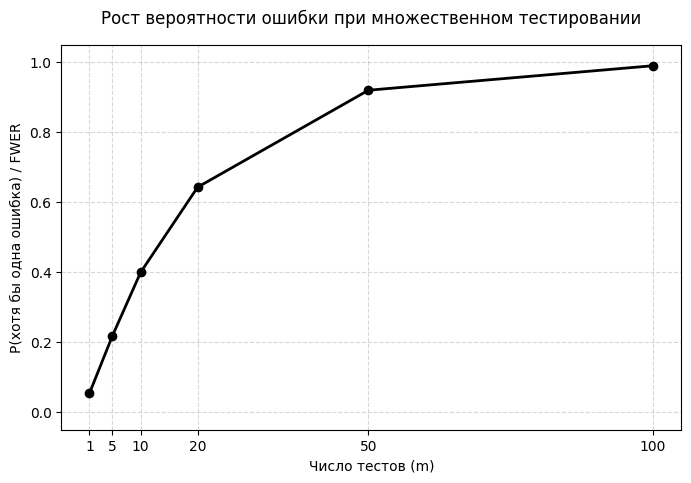

In [ ]:
n_comparisons = [1, 5, 10, 20, 50, 100]
fwer_estimates = {}

for m in n_comparisons:
    pvalues_slice = pvalues[:, :m]
    fwer = (pvalues_slice < alpha).any(axis=1).mean()
    fwer_estimates[m] = fwer
df_fwer = pd.DataFrame.from_dict(fwer_estimates, orient="index", columns=["estimate"])
print("Таблица значений FWER:")
print(df_fwer)
plt.figure(figsize=(8, 5))
plt.plot(df_fwer.index, df_fwer["estimate"], marker='o', color='black', linewidth=2)

plt.title("Рост вероятности ошибки при множественном тестировании", fontsize=12, pad=15)
plt.xlabel("Число тестов (m)", fontsize=10)
plt.ylabel("P(хотя бы одна ошибка) / FWER", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.ylim(-0.05, 1.05)
plt.xticks(n_comparisons)
plt.show()

### Задание 2

Повторите эксперимент, применив поправку Бонферрони. Постройте график зависимости FWER от числа сравнений.

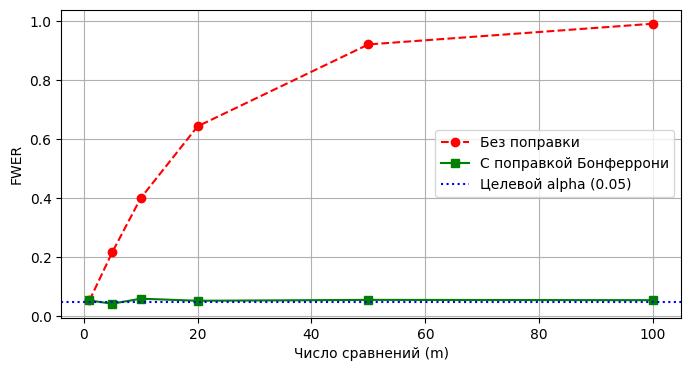

In [ ]:
n_comparisons = [1, 5, 10, 20, 50, 100]
fwer_raw = [(pvalues[:, :m] < alpha).any(axis=1).mean() for m in n_comparisons]
fwer_bonf = [(pvalues[:, :m] < (alpha / m)).any(axis=1).mean() for m in n_comparisons]

plt.figure(figsize=(8, 4))
plt.plot(n_comparisons, fwer_raw, 'r--o', label='Без поправки')
plt.plot(n_comparisons, fwer_bonf, 'g-s', label='С поправкой Бонферрони')
plt.axhline(alpha, color='blue', linestyle=':', label='Целевой alpha (0.05)')

plt.xlabel('Число сравнений (m)')
plt.ylabel('FWER')
plt.legend()
plt.grid(True)
plt.show()

### Задание 3

Теперь в каждом эксперименте первые **20** сравнений имеют истинный сдвиг среднего **0.6**, остальные **80** — по-прежнему нулевой.

In [ ]:
x = rng.normal(size=(1000, 100, 30))
y = rng.normal(size=x.shape)
y[:, :20] += 0.6

pvalues = stats.ttest_ind(x, y, axis=-1, equal_var=False).pvalue

Для поправок используем функцию `multipletests`.

In [ ]:
multipletests(pvalues[0], alpha=alpha, method="bonferroni")

(array([False, False, False, False, False,  True, False, False,  True,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False]),
 array([1.        , 1.        , 1.        , 1.        , 1.        ,
        0.01578376, 1.        , 1.        , 0.02736808, 1.        ,
        1.        , 1.        , 1.        , 1.        , 1.        

Сравним различные поправки для первого эксперимента.

In [ ]:
df = pd.DataFrame({
    "p-value": pvalues[0],
    "bonferroni": multipletests(pvalues[0], alpha=alpha, method="bonferroni")[1],
    "holm": multipletests(pvalues[0], alpha=alpha, method="holm")[1],
    "benjamini-hochberg": multipletests(pvalues[0], alpha=alpha, method="fdr_bh")[1],
})
df.sort_values(by="p-value").head()

,p-value,bonferroni,holm,benjamini-hochberg
5,0.000158,0.015784,0.015784,0.013684
8,0.000274,0.027368,0.027094,0.013684
18,0.001574,0.157426,0.154278,0.052475
56,0.004082,0.408222,0.395975,0.102056
17,0.007231,0.723149,0.694223,0.144630


Как и ранее, повторим оценку для 1, 5, 10, 20, 50 и 100 сравнений в эксперименте. Уменьшим число экспериментов до 100. Сравните результаты без поправки и с поправками Бонферрони (`bonferroni`), Холма (`holm`) и Бенджамини — Хохберга (`fdr_bh`). Поправку применяйте отдельно к каждому эксперименту, ко всем его 100 тестам.

Оформите в таблицу метрик:
- мощности — доли обнаруженных эффектов среди 20 истинных различий;
- доли ложных срабатываний среди 80 верных нулевых гипотез (FPR);
- долю экспериментов с хотя бы одним ложным срабатыванием (FWER);
- долю ложных срабатываний среди всех обнаружений (FDR).

In [ ]:
x = rng.normal(size=(250, 100, 30))
y = rng.normal(size=x.shape)
y[:, :20] += 0.6

pvalues = stats.ttest_ind(x, y, axis=-1, equal_var=False).pvalue

In [ ]:
alpha = 0.05
n_comparisons = [1, 5, 10, 20, 50, 100]
methods = ["raw", "bonferroni", "holm", "fdr_bh"]

results = []
for m in n_comparisons:
    p_slice = pvalues[:, :m]
    n_true_eff = min(20, m)
    n_true_null = max(0, m - 20)

    for method in methods:
        if method == "raw":
            reject = p_slice < alpha
        else:
            reject = np.array([
                multipletests(row, alpha=alpha, method=method)[0] for row in p_slice
            ])

        detected_true = reject[:, :n_true_eff]
        detected_noise = reject[:, 20:m] if m > 20 else np.zeros((pvalues.shape[0], 0), dtype=bool)

        power = detected_true.mean() if n_true_eff > 0 else np.nan
        fpr = detected_noise.mean() if n_true_null > 0 else np.nan
        fwer = (detected_noise.sum(axis=1) > 0).mean() if n_true_null > 0 else np.nan

        total_rejected = reject.sum(axis=1)
        false_rejected = detected_noise.sum(axis=1)
        fdr = np.mean(false_rejected / np.maximum(total_rejected, 1))

        results.append({
            "m": m,
            "Method": method,
            "Power (Мощность)": power,
            "FPR": fpr,
            "FWER": fwer,
            "FDR": fdr
        })

df_metrics = pd.DataFrame(results).set_index(["m", "Method"]).round(4)
df_metrics

Power (Мощность)     FPR   FWER     FDR
m   Method                                             
1   raw                   0.5680     NaN    NaN  0.0000
    bonferroni            0.5680     NaN    NaN  0.0000
    holm                  0.5680     NaN    NaN  0.0000
    fdr_bh                0.5680     NaN    NaN  0.0000
5   raw                   0.6200     NaN    NaN  0.0000
    bonferroni            0.3656     NaN    NaN  0.0000
    holm                  0.4544     NaN    NaN  0.0000
    fdr_bh                0.5504     NaN    NaN  0.0000
10  raw                   0.6304     NaN    NaN  0.0000
    bonferroni            0.2896     NaN    NaN  0.0000
    holm                  0.3512     NaN    NaN  0.0000
    fdr_bh                0.5532     NaN    NaN  0.0000
20  raw                   0.6344     NaN    NaN  0.0000
    bonferroni            0.2196     NaN    NaN  0.0000
    holm                  0.2478     NaN    NaN  0.0000
    fdr_bh                0.5392     NaN    NaN  0.0000
50  raw                   0.6344  0.0505  0.776  0.1030
    bonferroni            0.1394  0.0013  0.040  0.0122
    holm                  0.1424  0.0013  0.040  0.0122
    fdr_bh                0.3482  0.0095  0.252  0.0346
100 raw                   0.6344  0.0494  0.984  0.2316
    bonferroni            0.0978  0.0004  0.036  0.0141
    holm                  0.0988  0.0004  0.036  0.0139
    fdr_bh                0.2276  0.0036  0.240  0.0404

In [ ]:
def get_reject(p_slice, method):
    if method == "raw":
        return p_slice < alpha
    elif method == "bonferroni":
        m_tests = p_slice.shape[1]
        return np.clip(p_slice * m_tests, 0, 1) < alpha
    elif method == "fdr_bh":
        return stats.false_discovery_control(p_slice, axis=-1, method="bh") < alpha
    elif method == "holm":
        ranks = stats.rankdata(p_slice, method="ordinal", axis=-1)
        m_tests = p_slice.shape[1]
        p_corrected = np.clip(p_slice * (m_tests - ranks + 1), 0, 1)
        return p_corrected < alpha

results = []
for m in n_comparisons:
    p_slice = pvalues[:, :m]
    n_true_eff = min(20, m)
    n_true_null = max(0, m - 20)

    for method in ["raw", "bonferroni", "holm", "fdr_bh"]:
        rej = get_reject(p_slice, method)

        detected_true = rej[:, :n_true_eff]
        detected_noise = rej[:, 20:m] if m > 20 else np.zeros((pvalues.shape[0], 0), dtype=bool)

        power = detected_true.mean() if n_true_eff > 0 else np.nan
        fpr = detected_noise.mean() if n_true_null > 0 else np.nan
        fwer = (detected_noise.sum(axis=1) > 0).mean() if n_true_null > 0 else np.nan

        total_rejected = rej.sum(axis=1)
        false_rejected = detected_noise.sum(axis=1)
        fdr = np.mean(false_rejected / np.maximum(total_rejected, 1))

        results.append({
            "m": m,
            "Method": method,
            "Power (Мощность)": power,
            "FPR": fpr,
            "FWER": fwer,
            "FDR": fdr
        })

df_metrics = pd.DataFrame(results).set_index(["m", "Method"]).round(4)
df_metrics

Power (Мощность)     FPR   FWER     FDR
m   Method                                             
1   raw                   0.5680     NaN    NaN  0.0000
    bonferroni            0.5680     NaN    NaN  0.0000
    holm                  0.5680     NaN    NaN  0.0000
    fdr_bh                0.5680     NaN    NaN  0.0000
5   raw                   0.6200     NaN    NaN  0.0000
    bonferroni            0.3656     NaN    NaN  0.0000
    holm                  0.4624     NaN    NaN  0.0000
    fdr_bh                0.5504     NaN    NaN  0.0000
10  raw                   0.6304     NaN    NaN  0.0000
    bonferroni            0.2896     NaN    NaN  0.0000
    holm                  0.3544     NaN    NaN  0.0000
    fdr_bh                0.5532     NaN    NaN  0.0000
20  raw                   0.6344     NaN    NaN  0.0000
    bonferroni            0.2196     NaN    NaN  0.0000
    holm                  0.2478     NaN    NaN  0.0000
    fdr_bh                0.5392     NaN    NaN  0.0000
50  raw                   0.6344  0.0505  0.776  0.1030
    bonferroni            0.1394  0.0013  0.040  0.0122
    holm                  0.1424  0.0013  0.040  0.0122
    fdr_bh                0.3482  0.0095  0.252  0.0346
100 raw                   0.6344  0.0494  0.984  0.2316
    bonferroni            0.0978  0.0004  0.036  0.0141
    holm                  0.0988  0.0004  0.036  0.0139
    fdr_bh                0.2276  0.0036  0.240  0.0404

Визуализируйте метрики методов с помощью столбчатой диаграммы (`sns.barplot`). Отметьте уровень значимости горизонтальной пунктирной линией.

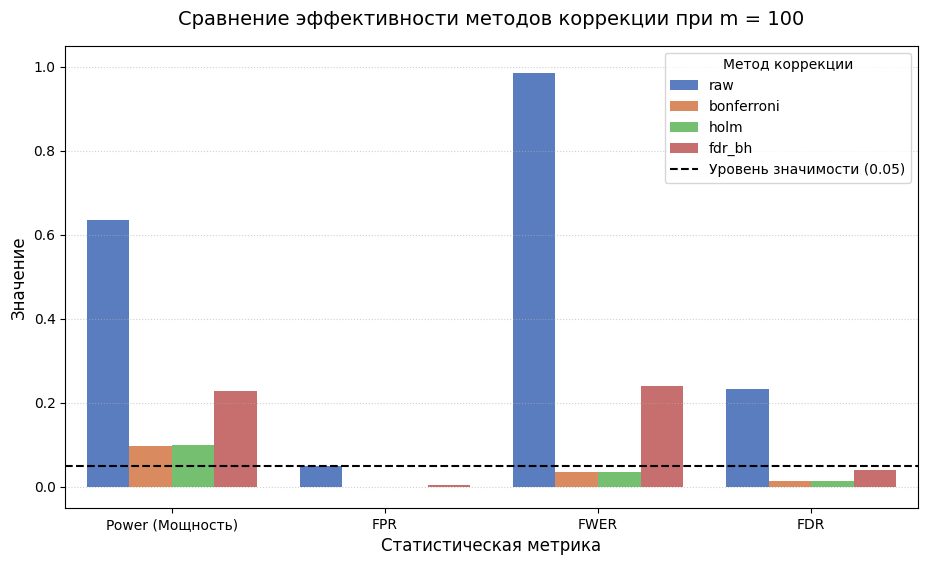

In [ ]:
df_m100 = df_metrics.xs(100, level="m").reset_index()

df_melted = df_m100.melt(
    id_vars="Method",
    value_vars=["Power (Мощность)", "FPR", "FWER", "FDR"],
    var_name="Metric",
    value_name="Value"
)

plt.figure(figsize=(11, 6))
sns.barplot(x="Metric", y="Value", hue="Method", data=df_melted, palette="muted")

plt.axhline(y=0.05, color="black", linestyle="--", linewidth=1.5, label="Уровень значимости (0.05)")

plt.title("Сравнение эффективности методов коррекции при m = 100", fontsize=14, pad=15)
plt.xlabel("Статистическая метрика", fontsize=12)
plt.ylabel("Значение", fontsize=12)
plt.ylim(-0.05, 1.05)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.legend(title="Метод коррекции", fontsize=10)

plt.show()